In [20]:
import torch
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_moons

In [21]:
def l2_norm(new_w, w):
    diff = new_w - w
    squarred_diff = diff ** 2
    sum_of_squares = torch.sum(squarred_diff)
    l2_norm = torch.sqrt(sum_of_squares)
    return l2_norm

In [22]:
#Генерація даних для кластеризація
X, y = make_blobs(n_samples=125, n_features=2, centers=4)


X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

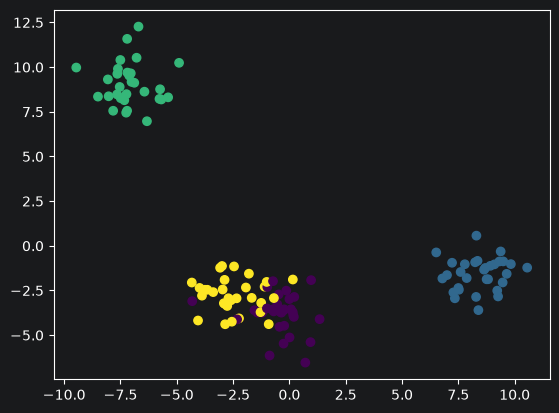

In [23]:
#Навчальні дані
plt.scatter(X[:, 0], X[:, 1], c=y)

In [32]:
def kmeans(data, k, max_iterations, min_distance):
    #Формуємо центроіди як рандомні k значень з data
    #Кожне з k значень - це два числа: X та y коoрдинати
    centroids = data[torch.randperm(len(data))[:k]] # [k, n_features]

    for _ in range(max_iterations):
        # Кластер - це группа схожих значень.
        # Задача даного алгоритму - віднести кожне значення з даних
        # до певного кластеру із k.
        # {0: [], 1: [], 2: [], 3: []}
        clusters = {i: [] for i in range(k)}

        for x in data:
            #Дистанція між ітерованими об'єктами
            distances = [l2_norm(x, centroid) for centroid in centroids]

            #Отримати індекс того кластеру, до якого даний об'єкт найближче
            corresponding_cluster = distances.index(min(distances))

            clusters[corresponding_cluster].append(x)

        old_centroids = centroids.clone()

        # Оновлюємо кожну центроіду як середнє значення кожного кластеру.
        for c in clusters.keys():
            centroids[c] = torch.mean(torch.stack(clusters[c]), dim=0)

        optimal = True

        for i in range(len(centroids)):
            if l2_norm(centroids[i], old_centroids[i]) > min_distance:
                optimal = False

        if optimal == True:
            break

    return clusters, centroids

In [28]:
# Функція візуалізації кластеризованих після алгоритму даних.
def plot_kmeans(clusters, centroids):
  colors = ["r", "g", "b", "orange", "y"]

  for centroid in centroids:
    plt.scatter(centroid[0], centroid[1], marker="x", s=100, c="black")

  for cluster_item in clusters.keys():
    for x in clusters[cluster_item]:
      plt.scatter(x[0], x[1], color=colors[cluster_item])

  plt.show()

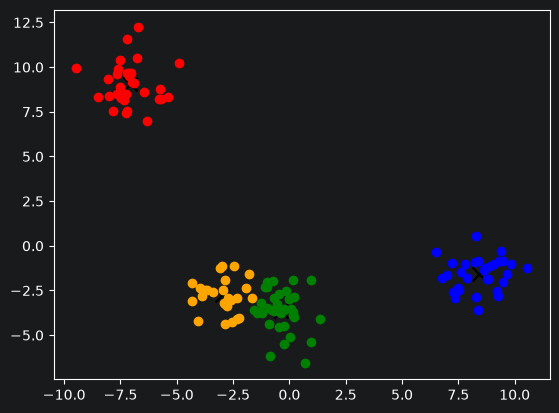

In [36]:
k = 4
max_iterations = 10
min_distance = 1e-4

clusters, centroids = kmeans(X, k, max_iterations, min_distance)
plot_kmeans(clusters, centroids)

In [37]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=4, max_iter=10)
km.fit(X)

labels = km.labels_
clusters = {i: X[labels == i] for i in range(km.n_clusters)}
centroids_sk = km.cluster_centers_

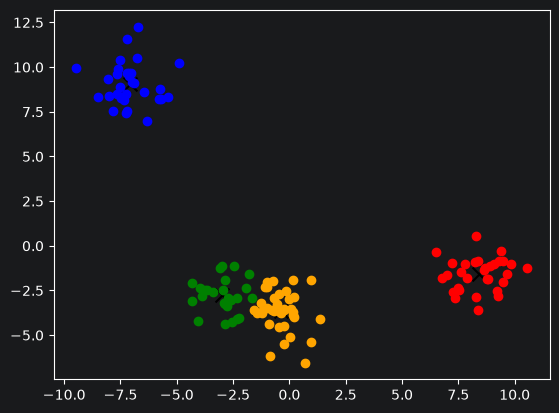

In [38]:
plot_kmeans(clusters, centroids_sk)

In [40]:
import pandas as pd

full_data = torch.cat([X, y.unsqueeze(-1)], dim=1).numpy()

pd.DataFrame(full_data, columns=["1_sign", "2_sign", 'segment'])

,1_sign,2_sign,segment
0,-3.881431,-2.789330,3.0
1,-6.436003,8.624724,2.0
2,8.388560,-3.598949,1.0
3,-2.593534,-3.047179,3.0
4,-4.315547,-3.097419,0.0
...,...,...,...
120,-7.823736,7.556991,2.0
121,-0.998331,-3.501085,0.0
122,-3.643673,-2.459803,3.0
123,-2.556038,-4.246348,3.0


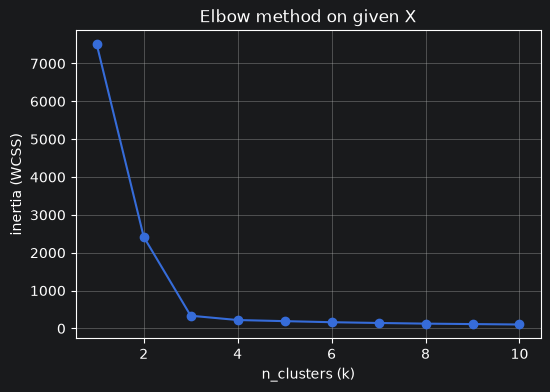

In [41]:
ks = range(1, 11)
inertias = []

for k in ks:
    km = KMeans(n_clusters=k, max_iter=10, n_init=10, random_state=42)
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("n_clusters (k)")
plt.ylabel("inertia (WCSS)")
plt.title("Elbow method on given X")
plt.grid(True)
plt.show()